In [7]:
import sys
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Python:    ', sys.version.split()[0])
print('pandas:    ', version('pandas'))
print('matplotlib:', version('matplotlib'))
print('seaborn:   ', version('seaborn'))

sns.set_theme(style='darkgrid')

listings = pd.read_csv('data/listings_clean.csv', parse_dates=['first_review', 'last_review'])

print(listings.shape)


Python:     3.14.10
pandas:     3.0.5
matplotlib: 3.11.2
seaborn:    0.13.2
(4574, 73)


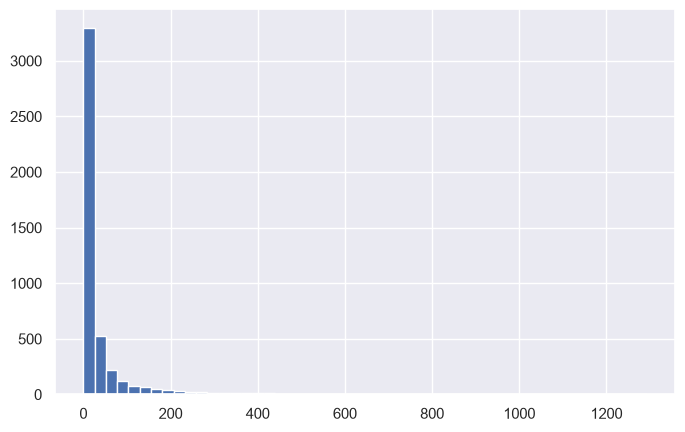

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings['number_of_reviews'], bins=50)
plt.show()


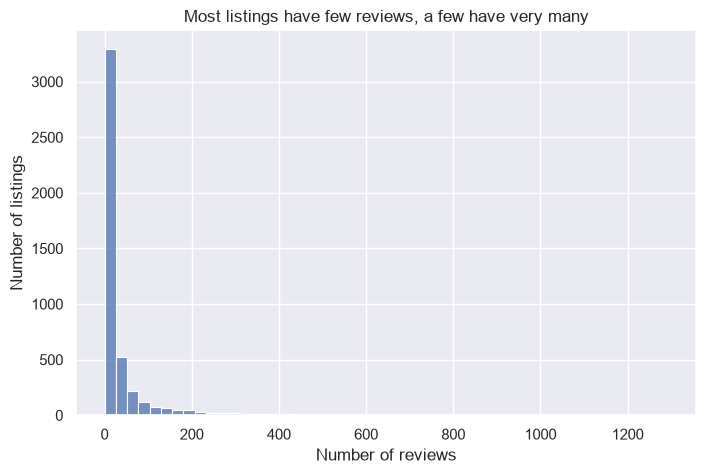

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)
ax.set_title('Most listings have few reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
plt.show()

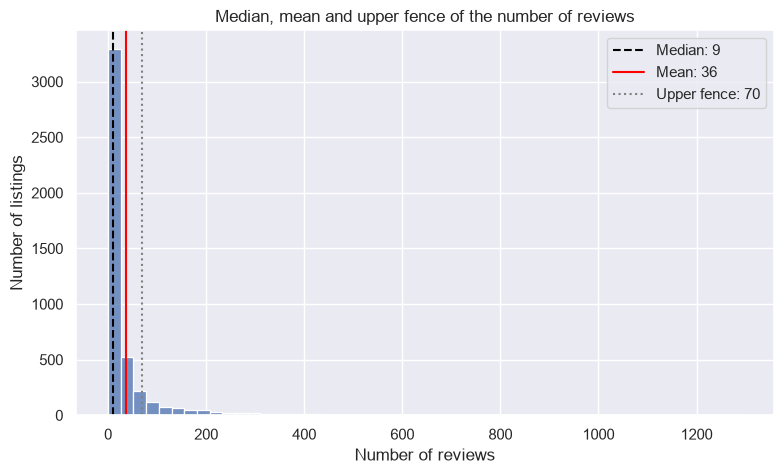

In [ ]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'Median: {median:.0f}')
ax.axvline(mean, color='red', linestyle='-', label=f'Mean: {mean:.0f}')
ax.axvline(upper_fence, color='gray', linestyle=':', label=f'Upper fence: {upper_fence:.0f}')

ax.set_title('Median, mean and upper fence of the number of reviews')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()


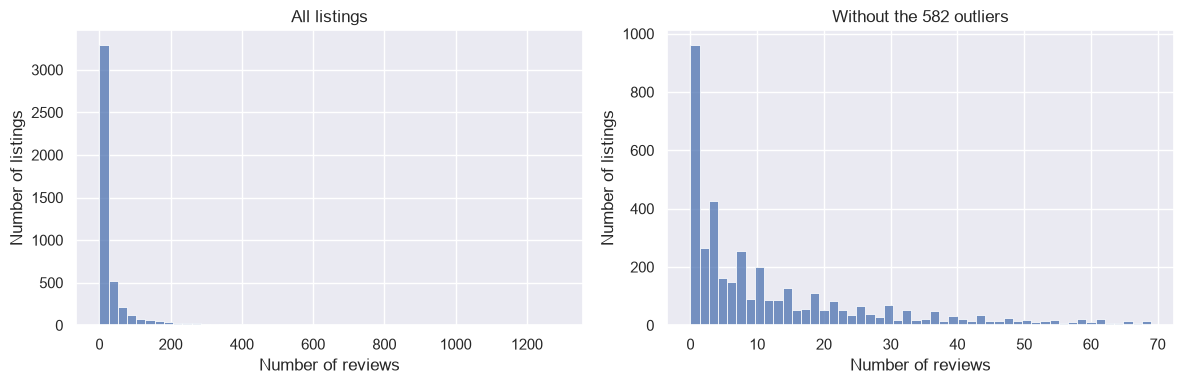

In [ ]:
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

listings['reviews_outlier'] = listings['number_of_reviews'] > upper_fence
n_outliers = listings['reviews_outlier'].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
axes[0].set_title('All listings')

sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])
axes[1].set_title(f'Without the {n_outliers} outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

90 listings are above 300 reviews


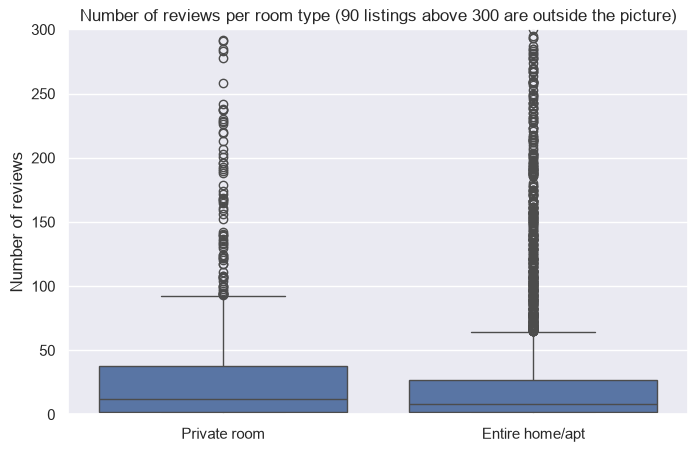

In [ ]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

# Count the listings above 300 reviews (they are outside the picture)
n_outside = (two_types['number_of_reviews'] > 300).sum()
print(n_outside, 'listings are above 300 reviews')

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Number of reviews per room type ({n_outside} listings above 300 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Number of reviews')

plt.show()

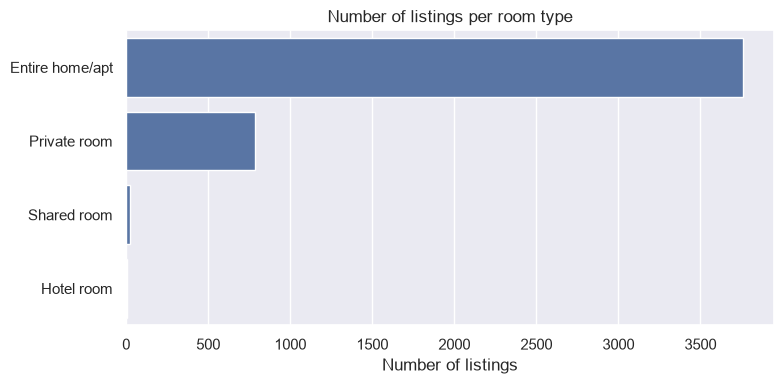

In [ ]:
order = listings['room_type'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 4))

sns.countplot(data=listings, y='room_type', order=order, ax=ax)

ax.set_title('Number of listings per room type')
ax.set_xlabel('Number of listings')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

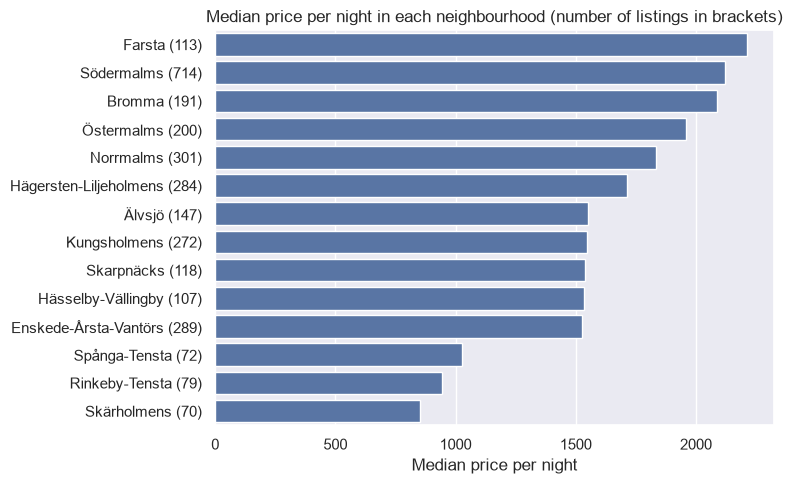

In [ ]:
by_area = (
    listings.groupby('neighbourhood_cleansed')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .reset_index()
)

by_area['label'] = by_area['neighbourhood_cleansed'] + ' (' + by_area['count'].astype(str) + ')'

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x='median', y='label', ax=ax)

ax.set_title('Median price per night in each neighbourhood (number of listings in brackets)')
ax.set_xlabel('Median price per night')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
by_area


,neighbourhood_cleansed,median,count,label
0,Farsta,2213.880,113,Farsta (113)
1,Södermalms,2119.100,714,Södermalms (714)
2,Bromma,2089.000,191,Bromma (191)
3,Östermalms,1960.145,200,Östermalms (200)
4,Norrmalms,1834.000,301,Norrmalms (301)
5,Hägersten-Liljeholmens,1712.000,284,Hägersten-Liljeholmens (284)
6,Älvsjö,1548.900,147,Älvsjö (147)
7,Kungsholmens,1545.500,272,Kungsholmens (272)
8,Skarpnäcks,1537.735,118,Skarpnäcks (118)
9,Hässelby-Vällingby,1533.600,107,Hässelby-Vällingby (107)


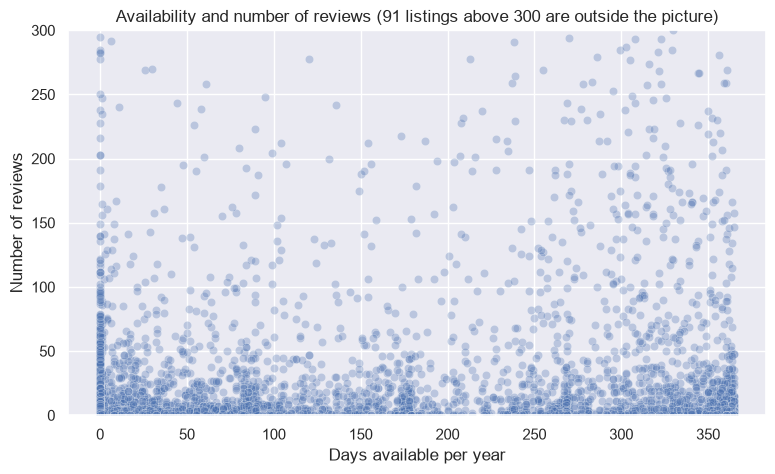

In [ ]:
n_outside = (listings['number_of_reviews'] > 300).sum()

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', alpha=0.3, ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Availability and number of reviews ({n_outside} listings above 300 are outside the picture)')
ax.set_xlabel('Days available per year')
ax.set_ylabel('Number of reviews')

plt.show()

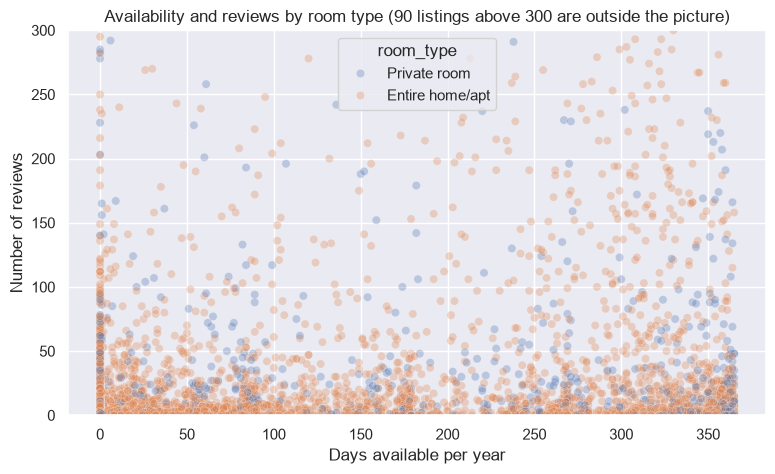

In [ ]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]
n_outside = (two_types['number_of_reviews'] > 300).sum()

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=two_types, x='availability_365', y='number_of_reviews',
                hue='room_type', alpha=0.3, ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Availability and reviews by room type ({n_outside} listings above 300 are outside the picture)')
ax.set_xlabel('Days available per year')
ax.set_ylabel('Number of reviews')

plt.show()

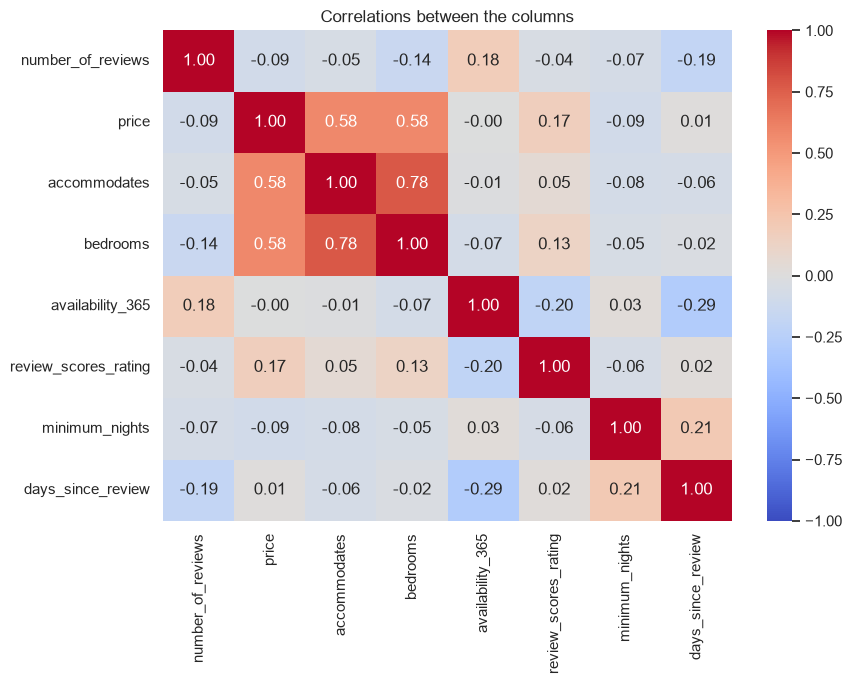

In [ ]:
columns = ['number_of_reviews', 'price', 'accommodates', 'bedrooms',
           'availability_365', 'review_scores_rating', 'minimum_nights',
           'days_since_review']

corr = listings[columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)

ax.set_title('Correlations between the columns')

plt.tight_layout()
plt.show()

Numbers show some correlation between price, accommodates and bedrooms, but nowhere else.

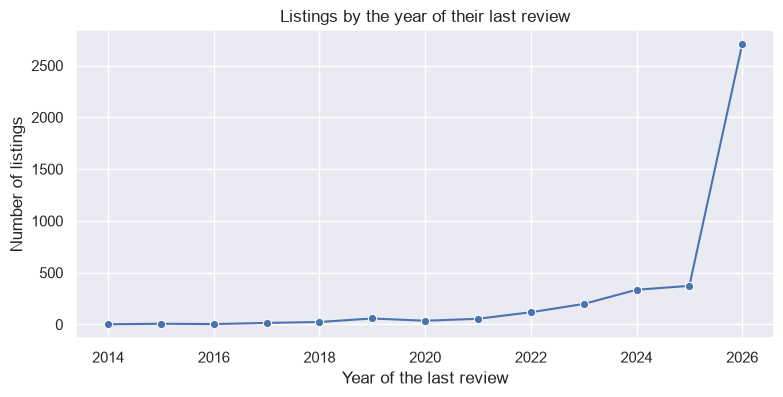

In [ ]:
per_year = listings['last_review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))

sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax=ax)

ax.set_title('Listings by the year of their last review')
ax.set_xlabel('Year of the last review')
ax.set_ylabel('Number of listings')

plt.show()

Listings from earlier years can have been deleted entirely, so there might have been more listings.
A last review from this year means the listning probably still is active.

room_type
Entire home/apt    4.92
Private room       4.89
Name: review_scores_rating, dtype: float64


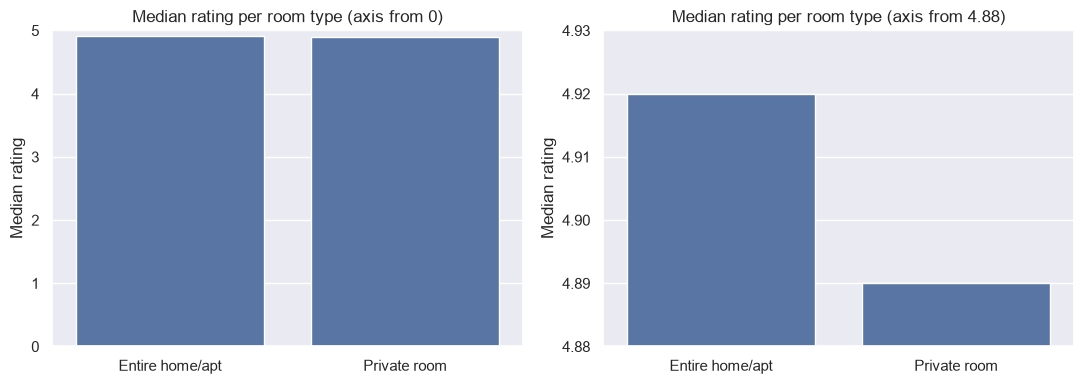

In [ ]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

medians = two_types.groupby('review_scores_rating'.replace('review_scores_rating', 'room_type'))['review_scores_rating'].median()
print(medians)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(x=medians.index, y=medians.values, ax=axes[0])
axes[0].set_ylim(0, 5)
axes[0].set_title('Median rating per room type (axis from 0)')

sns.barplot(x=medians.index, y=medians.values, ax=axes[1])
axes[1].set_ylim(4.88, 4.93)
axes[1].set_title('Median rating per room type (axis from 4.88)')

for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('Median rating')

plt.tight_layout()
plt.show()

In [8]:
difference = (listings['price'] * listings['estimated_occupancy_l365d'] - listings['estimated_revenue_l365d']).abs()

print(difference.max())
print((listings['estimated_occupancy_l365d'] == 0).sum())

0.5
1797
